In [ ]:
!pip install pandas numpy matplotlib seaborn plotly SPARQLWrapper

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from SPARQLWrapper import SPARQLWrapper, JSON

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sparql_2026-11-05_17-30-08Z.csv to sparql_2026-11-05_17-30-08Z.csv


In [ ]:
df = pd.read_csv("sparql_2026-11-05_17-30-08Z.csv")

display(df.head())

,event,date,place
0,http://dbpedia.org/resource/1900_Carlist_Suble...,1900-10-28,http://dbpedia.org/resource/Badalona
1,http://dbpedia.org/resource/Action_of_11_March...,1727-03-11,http://dbpedia.org/resource/Cádiz
2,http://dbpedia.org/resource/Action_of_12_Decem...,1782-12-12,"http://dbpedia.org/resource/Ferrol,_Spain"
3,http://dbpedia.org/resource/Action_of_16_April...,1755-04-16,http://dbpedia.org/resource/Benidorm
4,http://dbpedia.org/resource/Action_of_16_March...,1782-03-16,http://dbpedia.org/resource/Strait_of_Gibraltar


In [ ]:
# Extract the year directly from the text
df["year"] = df["date"].str[:4].astype(int)

# Calculate the century
df["century"] = ((df["year"] - 1) // 100) + 1

# Calculate the decade
df["decade"] = (df["year"] // 10) * 10

# Extract readable names for events and places
df["event_name"] = df["event"].str.split("/").str[-1]
df["place_name"] = df["place"].str.split("/").str[-1]

display(df.head())

,event,date,place,year,century,decade,event_name,place_name
0,http://dbpedia.org/resource/1900_Carlist_Suble...,1900-10-28,http://dbpedia.org/resource/Badalona,1900,19,1900,1900_Carlist_Sublevation,Badalona
1,http://dbpedia.org/resource/Action_of_11_March...,1727-03-11,http://dbpedia.org/resource/Cádiz,1727,18,1720,Action_of_11_March_1727,Cádiz
2,http://dbpedia.org/resource/Action_of_12_Decem...,1782-12-12,"http://dbpedia.org/resource/Ferrol,_Spain",1782,18,1780,Action_of_12_December_1782,"Ferrol,_Spain"
3,http://dbpedia.org/resource/Action_of_16_April...,1755-04-16,http://dbpedia.org/resource/Benidorm,1755,18,1750,Action_of_16_April_1755,Benidorm
4,http://dbpedia.org/resource/Action_of_16_March...,1782-03-16,http://dbpedia.org/resource/Strait_of_Gibraltar,1782,18,1780,Action_of_16_March_1782,Strait_of_Gibraltar


In [ ]:
events = df.drop_duplicates(subset=["event"]).copy()

In [ ]:
date_conflicts = df.groupby("event")["date"].nunique()

print("Events with multiple dates:",
      (date_conflicts > 1).sum())

Events with multiple dates: 5


1. How is the dataset structured in terms of historical events and associated locations?

In [ ]:
# General information
total_records = len(df)
unique_events = df["event"].nunique()
unique_places = df["place"].nunique()

print("Total records:", total_records)
print("Unique events:", unique_events)
print("Unique places:", unique_places)

# Number of places associated with each event
places_per_event = df.groupby("event")["place"].nunique()

print("\nPlaces per event:")
print(places_per_event.value_counts().sort_index())

# Events associated with more than one place
multiple_places = places_per_event[places_per_event > 1]

print("\nEvents with multiple places:", len(multiple_places))

Total records: 310
Unique events: 256
Unique places: 174

Places per event:
place
1    209
2     45
3      2
Name: count, dtype: int64

Events with multiple places: 47


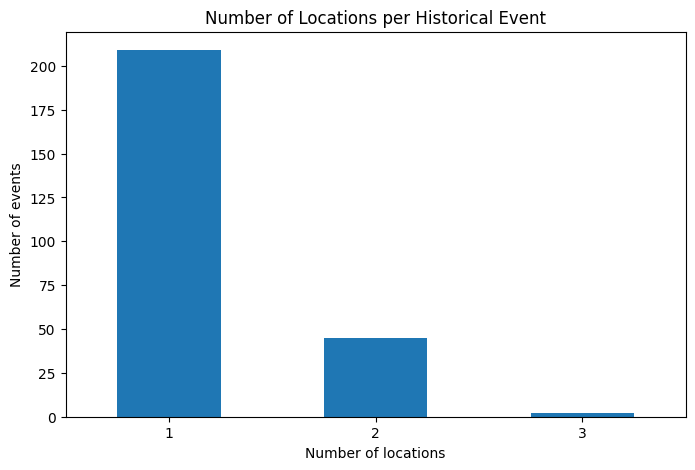

In [ ]:
places_per_event.value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Number of Locations per Historical Event")
plt.xlabel("Number of locations")
plt.ylabel("Number of events")
plt.xticks(rotation=0)
plt.show()

2. How complete and reliable is the temporal and geographical information?

In [ ]:
# Missing values
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

print("Missing values:")
print(missing_values)

print("\nMissing percentage:")
print(missing_percentage)

# Exact duplicates
print("\nExact duplicates:", df.duplicated().sum())

# Check valid dates
valid_dates = df["date"].str.match(
    r"^\d{4}-\d{2}-\d{2}$"
)

print("\nInvalid date formats:", (~valid_dates).sum())

# Check for inconsistent dates
date_conflicts = df.groupby("event")["date"].nunique()

print("\nEvents with conflicting dates:",
      (date_conflicts > 1).sum())

# Check URIs
print("\nInvalid event URIs:",
      (~df["event"].str.startswith(
          "http://dbpedia.org/resource/"
      )).sum())

Missing values:
event         0
date          0
place         0
year          0
century       0
decade        0
event_name    0
place_name    0
dtype: int64

Missing percentage:
event         0.0
date          0.0
place         0.0
year          0.0
century       0.0
decade        0.0
event_name    0.0
place_name    0.0
dtype: float64

Exact duplicates: 0

Invalid date formats: 0

Events with conflicting dates: 5

Invalid event URIs: 0


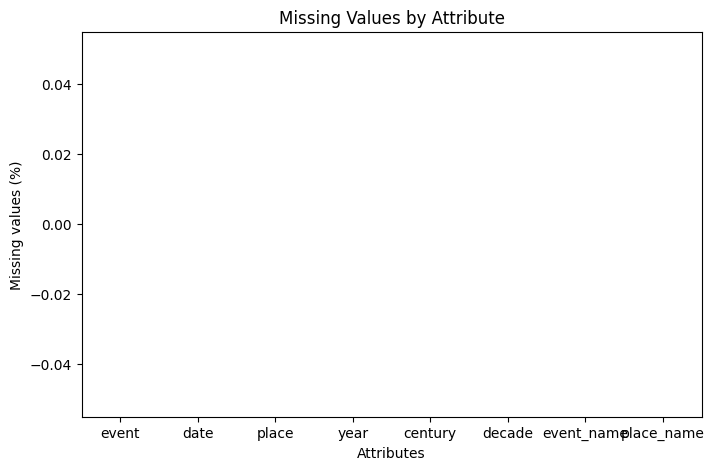

In [ ]:
missing_percentage.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Missing Values by Attribute")
plt.xlabel("Attributes")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=0)
plt.show()

3. How are historical events distributed across centuries?

In [ ]:
# Number of unique events per century
events_per_century = (
    events.groupby("century")["event"]
    .nunique()
    .sort_index()
)

# Percentage
percentage_per_century = (
    events_per_century /
    events_per_century.sum() * 100
)

results = pd.DataFrame({
    "Events": events_per_century,
    "Percentage": percentage_per_century
})

display(results)

,Events,Percentage
century,,
15,17,6.640625
16,17,6.640625
17,25,9.765625
18,51,19.921875
19,146,57.031250


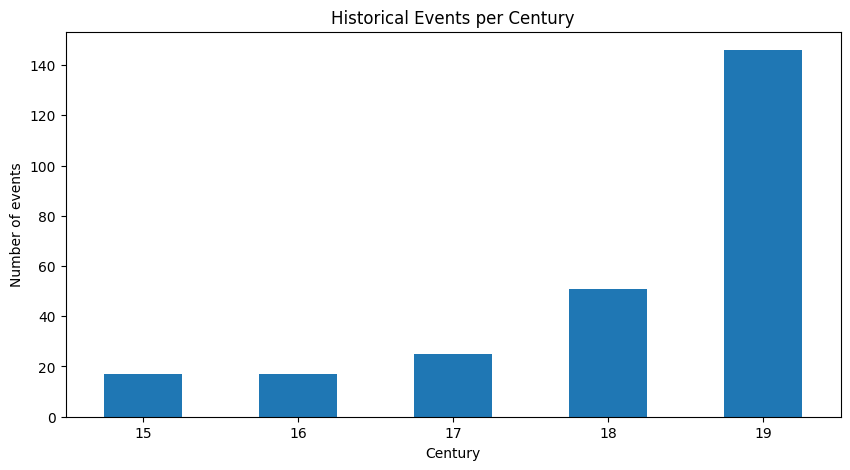

In [ ]:
events_per_century.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Historical Events per Century")
plt.xlabel("Century")
plt.ylabel("Number of events")
plt.xticks(rotation=0)
plt.show()

4. How has the frequency of historical events evolved over time?

In [ ]:
events_per_year = (
    events.groupby("year")["event"]
    .nunique()
    .sort_index()
)

display(events_per_year)

,event
year,
1407,1
1412,1
1415,1
1419,1
1431,1
...,...
1839,1
1860,1
1873,3


In [ ]:
events_per_decade = (
    events.groupby("decade")["event"]
    .nunique()
    .sort_index()
)

display(events_per_decade)

,event
decade,
1400,1
1410,3
1430,2
1440,1
1450,1
1460,1
1470,1
1480,4
1490,3


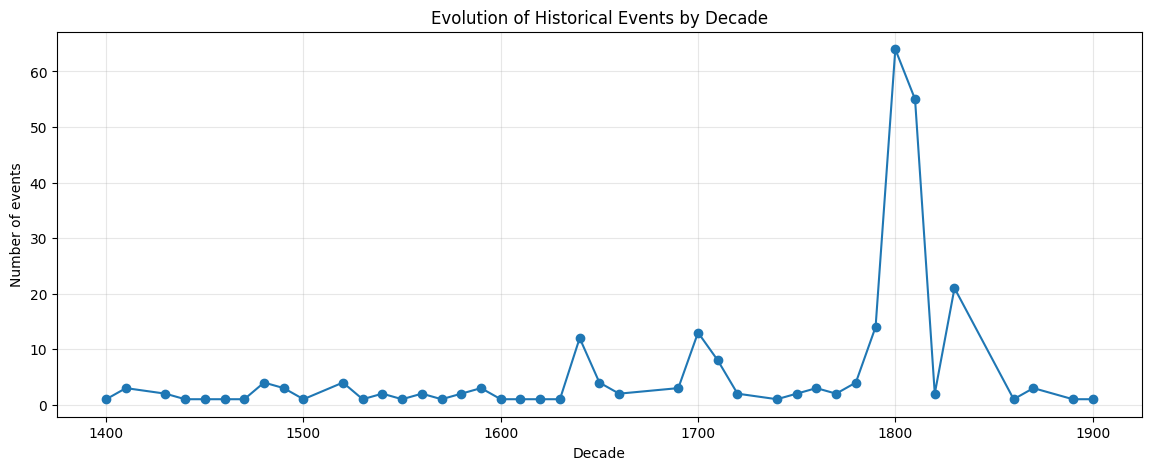

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    events_per_decade.index,
    events_per_decade.values,
    marker="o"
)

plt.title("Evolution of Historical Events by Decade")
plt.xlabel("Decade")
plt.ylabel("Number of events")
plt.grid(alpha=0.3)
plt.show()

5. Are there particular historical periods with a significantly higher concentration of events?

In [ ]:
# Group events into 20-year periods
events["period_20"] = (events["year"] // 20) * 20

events_per_period = (
    events.groupby("period_20")["event"]
    .nunique()
    .sort_index()
)

# Identify the most represented periods
top_periods = events_per_period.sort_values(
    ascending=False
).head(10)

print("Top 10 historical periods:")
display(top_periods)

# Comparison with the average
mean_events = events_per_period.mean()

print("Average events per period:", mean_events)

Top 10 historical periods:


,event
period_20,
1800,119
1820,23
1700,21
1780,18
1640,16
1480,7
1520,5
1760,5
1580,5


Average events per period: 10.24


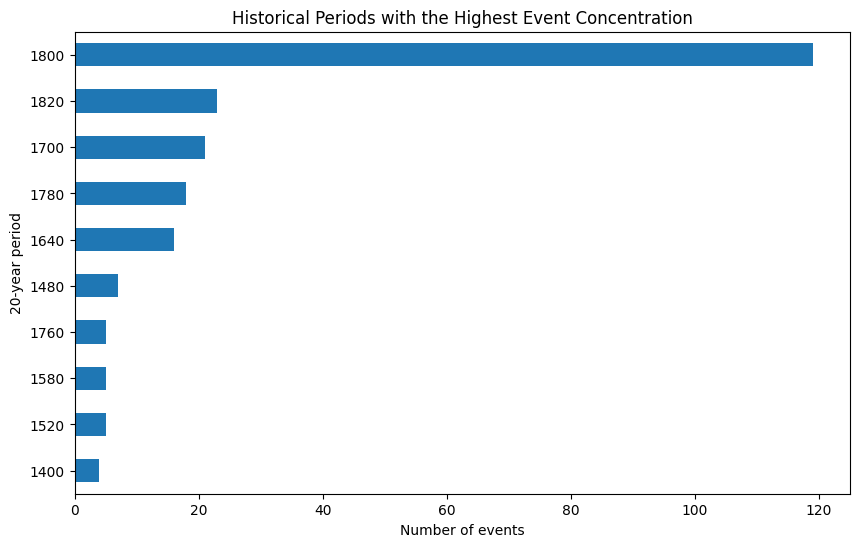

In [ ]:
top_periods.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Historical Periods with the Highest Event Concentration")
plt.xlabel("Number of events")
plt.ylabel("20-year period")
plt.show()

6. Which geographical locations are most frequently associated with historical events?

In [ ]:
events_per_place = (
    df.groupby("place_name")["event"]
    .nunique()
    .sort_values(ascending=False)
)

# Top 15 places
top_places = events_per_place.head(15)

# Percentage relative to the total number of events
place_percentage = (
    top_places / df["event"].nunique() * 100
)

results_places = pd.DataFrame({
    "Events": top_places,
    "Percentage": place_percentage
})

display(results_places)

,Events,Percentage
place_name,,
Barcelona,10,3.906250
Cádiz,10,3.906250
Navarre,10,3.906250
Strait_of_Gibraltar,8,3.125000
Basque_Country_(autonomous_community),8,3.125000
Bay_of_Cádiz,6,2.343750
Girona,6,2.343750
Galicia_(Spain),6,2.343750
Peñón_de_Vélez_de_la_Gomera,5,1.953125


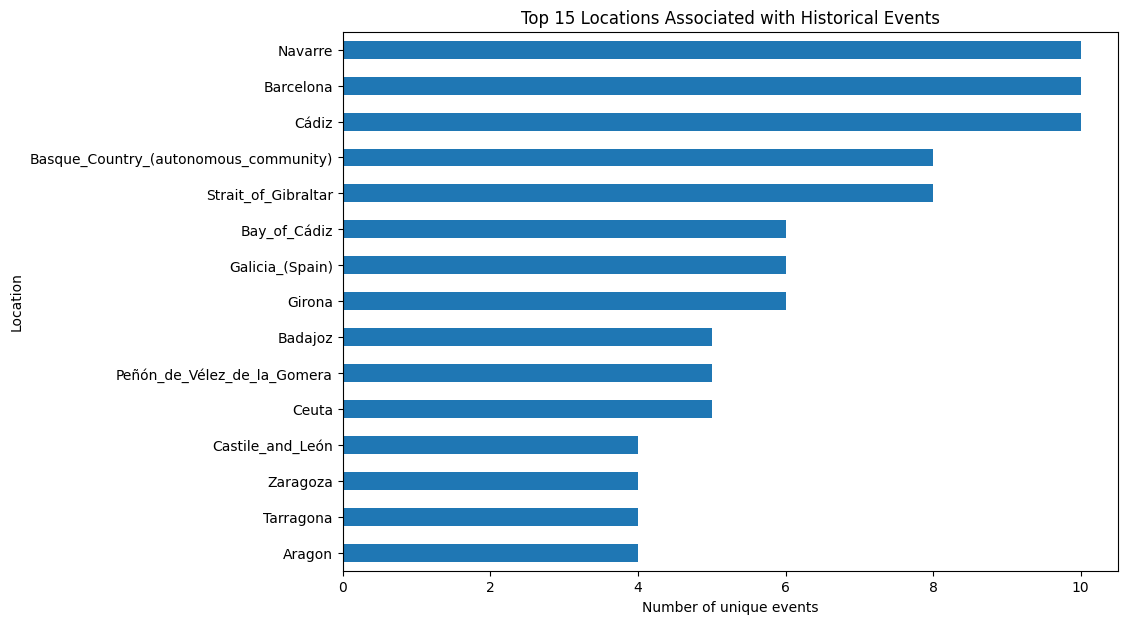

In [ ]:
top_places.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top 15 Locations Associated with Historical Events")
plt.xlabel("Number of unique events")
plt.ylabel("Location")
plt.show()

7. Are there geographical locations that remain historically significant across multiple centuries?

In [ ]:
# Number of different centuries per location
centuries_per_place = (
    df.groupby("place_name")["century"]
    .nunique()
    .sort_values(ascending=False)
)

# Number of events per location
events_per_place = (
    df.groupby("place_name")["event"]
    .nunique()
)

# Combine both statistics
historical_significance = pd.DataFrame({
    "Number of centuries": centuries_per_place,
    "Number of events": events_per_place
})

historical_significance = (
    historical_significance
    .sort_values(
        by=["Number of centuries", "Number of events"],
        ascending=False
    )
)

display(historical_significance.head(15))

,Number of centuries,Number of events
place_name,,
Strait_of_Gibraltar,4,8
Bay_of_Cádiz,4,6
Ceuta,4,5
Barcelona,3,10
Cádiz,3,10
Navarre,3,10
Galicia_(Spain),3,6
Girona,3,6
Málaga,3,4


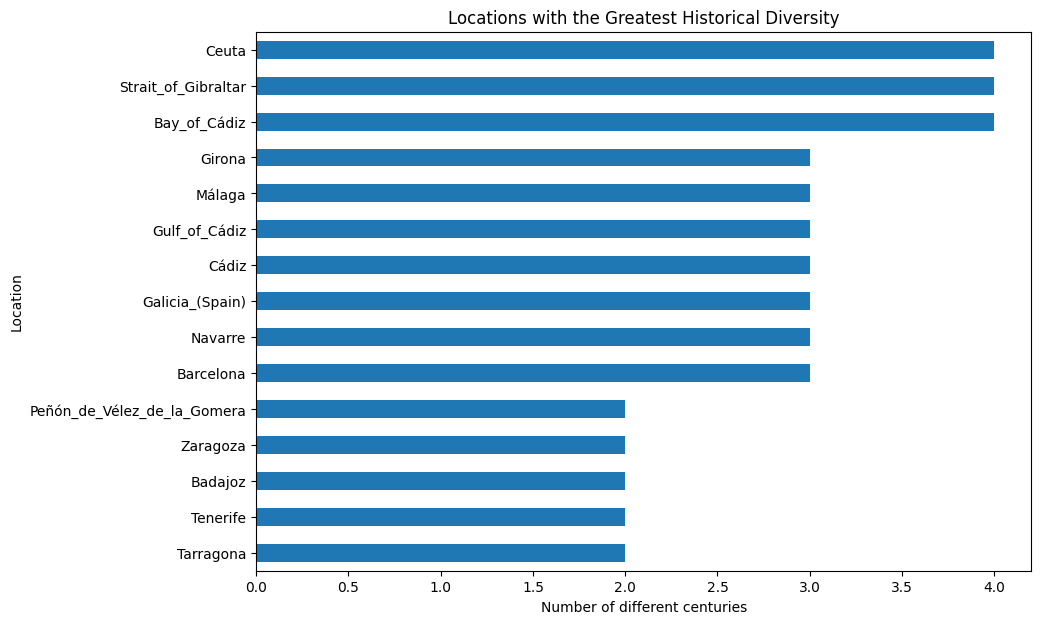

In [ ]:
historical_significance.head(15)[
    "Number of centuries"
].sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Locations with the Greatest Historical Diversity")
plt.xlabel("Number of different centuries")
plt.ylabel("Location")
plt.show()

8. What types of historical events are most frequently represented in the dataset?

In [ ]:
import pandas as pd
import re

# 1. Extract unique event URIs
events_list = events["event"].dropna().unique()

# 2. Clean event URIs
clean_events = []

for event in events_list:
    event = str(event).strip()

    # Extract URL if it is stored as a Markdown link
    match = re.search(r'https?://[^\s\]\)]+', event)

    if match:
        event = match.group(0)

    # Keep only valid DBpedia resource URIs
    if event.startswith("http://dbpedia.org/resource/"):
        clean_events.append(event)

# Remove duplicates
events_list = list(dict.fromkeys(clean_events))

print("Total valid event URIs:", len(events_list))

# 3. Query DBpedia in batches of 100 events
all_results = []

for i in range(0, len(events_list), 100):

    batch = events_list[i:i+100]

    event_values = "\n".join(
        f"<{event}>" for event in batch
    )

    query_events = f"""
    PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
    PREFIX dbo: <http://dbpedia.org/ontology/>
    PREFIX dct: <http://purl.org/dc/terms/>

    SELECT DISTINCT ?event ?type ?category
    WHERE {{
        VALUES ?event {{
            {event_values}
        }}

        OPTIONAL {{
            ?event rdf:type ?type .

            FILTER(
                STRSTARTS(
                    STR(?type),
                    "http://dbpedia.org/ontology/"
                )
            )
        }}

        OPTIONAL {{
            ?event dct:subject ?category .
        }}
    }}
    """

    try:
        batch_results = execute_sparql(query_events)
        all_results.append(batch_results)

        print(
            f"Processed {min(i+100, len(events_list))}"
            f"/{len(events_list)} events"
        )

    except Exception as e:
        print(f"Error in batch {i//100 + 1}: {e}")

# 4. Combine all results
if all_results:
    results_events = pd.DataFrame([
        row for batch in all_results
        for row in batch
    ])

    # Clean URI values
    for col in ["event", "type", "category"]:
        results_events[col] = results_events[col].apply(
            lambda x: re.search(
                r'https?://[^\]]+',
                x["value"]
            ).group(0) if isinstance(x, dict) and "value" in x else None
        )

    # Extract readable names
    results_events["event_name"] = (
        results_events["event"].str.split("/").str[-1]
    )

    results_events["type_name"] = (
        results_events["type"].str.split("/").str[-1]
    )

    results_events["category_name"] = (
        results_events["category"]
        .str.split("/")
        .str[-1]
        .str.replace("_", " ", regex=False)
        .str.replace("Category:", "", regex=False)
    )

    # Display readable columns
    display(
        results_events[
            ["event_name", "type_name", "category_name"]
        ].head(10)
    )

else:
    print("No results were retrieved.")

Total valid event URIs: 256
Processed 100/256 events
Processed 200/256 events
Processed 256/256 events


,event_name,type_name,category_name
0,Action_of_28–29_December_1669,Event,1669 in England
1,Action_of_28–29_December_1669,Event,Military history of Gibraltar
2,Action_of_28–29_December_1669,Event,Naval battles involving the Regency of Algiers
3,Action_of_28–29_December_1669,Event,Conflicts in 1669
4,Action_of_28–29_December_1669,Event,Naval battles involving England
5,Action_of_28–29_December_1669,Event,17th century in the Regency of Algiers
6,Action_of_28–29_December_1669,MilitaryConflict,1669 in England
7,Action_of_28–29_December_1669,MilitaryConflict,Military history of Gibraltar
8,Action_of_28–29_December_1669,MilitaryConflict,Naval battles involving the Regency of Algiers
9,Action_of_28–29_December_1669,MilitaryConflict,Conflicts in 1669
